# Spatial GRN Integration of the Dentate Gyrus

## Step2:Gene Regulatory Network uisng SCENIC+:
## Tutorial 2a: pycisTopic

**Author:** Xuan Cao  
**Affiliation:** Icahn School of Medicine at Mount Sinai  
**Email:** xuan.cao@mssm.edu  

**Contributors:** Donghoon Lee, Panos Roussos  

**Date:** Jun 12, 2026  

---

### Overview

This notebook demonstrates the pycisTopic workflow used to construct chromatin accessibility profiles for downstream SCENIC+ analysis in the dentate gyrus. Starting from single-nucleus ATAC-seq data, we generate pseudobulk accessibility profiles, perform peak calling, build a cisTopic object, identify latent regulatory topics, and characterize differentially accessible regions across cell populations.

The resulting cisTopic object and topic-derived regulatory regions provide the foundation for subsequent SCENIC+ analyses, including enhancer-to-gene linking, transcription factor motif enrichment, and gene regulatory network (GRN) inference. Ultimately, these analyses enable the integration of chromatin accessibility and transcriptomic information to investigate the regulatory programs underlying dentate gyrus development and maturation.

### Input:

Single-nucleus ATAC-seq fragments.tsv data from the dentate gyrus<br>
Cell-type annotations or grouping information<br>
Reference genome and chromosome sizes<br>

### Output:

Pseudobulk ATAC-seq profiles<br>
Consensus peak set<br>
cisTopic object<br>
Topic models and topic quality metrics<br>
Binarized topics and topic-associated regions<br>
Differentially accessible regions (DARs)<br>
Exported cisTopic object for downstream SCENIC+ GRN analyses<br>

### scenicplus version 
0.1.dev454+g9320635

### Install conda environment
Adapted from the SCENIC+ GitHub repository<br>
conda create --name scenicplus python=3.11 -y<br>
conda activate scenicplus<br>
git clone https://github.com/aertslab/scenicplus  ## should be set the version <br>
cd scenicplus<br>
pip install .<br>


### Contents
1. Data loading 
2. Generate pseudobulk ATAC-seq profiles  
3. Peak Calling  
4. Creating cisTopic object
5. Running topic model
6. Visualization of topics
7. Topic binarization & QC
8. Differentially Accessible Regions (DARs)
9. Export cistopic object
  

# Imports

In [1]:
import numpy as np
import scanpy as sc
import pandas as pd
import pyranges as pr

sc.set_figure_params(scanpy=True, dpi=100, dpi_save=150, fontsize=12)
sc.set_figure_params(dpi=100, color_map = 'viridis_r')
sc.settings.verbosity = 1
sc.logging.print_header()
from matplotlib.pyplot import rc_context

import gc

import sys
import os
import pickle

import warnings
warnings.simplefilter(action='ignore')
import pycisTopic
pycisTopic.__version__

/sc/arion/projects/YuanLab/gcproj/xuan/anaconda3/envs/scenicplus/lib/python3.8/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/sc/arion/projects/YuanLab/gcproj/xuan/anaconda3/envs/scenicplus/lib/python3.8/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/sc/arion/pr

scanpy==1.8.2 anndata==0.8.0 umap==0.5.3 numpy==1.23.5 scipy==1.9.3 pandas==1.5.1 scikit-learn==1.3.2 statsmodels==0.13.5 python-igraph==0.10.2 pynndescent==0.5.11


/sc/arion/projects/YuanLab/gcproj/xuan/anaconda3/envs/scenicplus/lib/python3.8/site-packages/umap/umap_.py:660: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()


'1.0.2.dev9+gaf3977c'

# Set dirs

In [2]:
master_dir = 'SpatialGRN/Output'
cistopic_dir = f'{master_dir}/02a.pycisTopic'
tmp_dir = "tmp/"
log_dir=f'{cistopic_dir}/00.log'

if not os.path.exists(master_dir):
    os.makedirs(master_dir)
    
if not os.path.exists(cistopic_dir):
    os.makedirs(cistopic_dir)
    
if not os.path.exists(tmp_dir):
    os.makedirs(tmp_dir)

if not os.path.exists(tmp_dir):
    os.makedirs(log_dir)

# 1. Data loading

## 1.1 get cell type from snRNA

In [28]:
file_rna = 'data/human_DG_snrna.h5ad'
snrna = sc.read_h5ad(file_rna)
cell_data = snrna.obs
cell_data["sample_id"] = 'human_DG' 
cell_data['barcode'] = cell_data.index.copy()
cell_data.index = cell_data.index + '#human_DG'
# cell_data.barcode or rownames of cell_data should the same with fragement_file
cell_data.head()

,class,subclass,subtype,sample_id,barcode
CGGACCTAGGAACCGG-1_BICCN-set1-1#human_DG,EN,DG,DG_PROX1_SGCZ,human_DG,CGGACCTAGGAACCGG-1_BICCN-set1-1
AATCCCTGTAGCCTCC-1_BICCN-set1-1#human_DG,EN,DG,DG_PROX1_SGCZ,human_DG,AATCCCTGTAGCCTCC-1_BICCN-set1-1
ACAGCGCTCAGGCCTA-1_BICCN-set1-1#human_DG,EN,DG,DG_PROX1_PDLIM5,human_DG,ACAGCGCTCAGGCCTA-1_BICCN-set1-1
CATTATGAGGCATTAC-1_BICCN-set1-1#human_DG,EN,DG,DG_PROX1_PDLIM5,human_DG,CATTATGAGGCATTAC-1_BICCN-set1-1
ATTTAGCCAACAGCCT-1_BICCN-set1-1#human_DG,EN,DG,DG_PROX1_SGCZ,human_DG,ATTTAGCCAACAGCCT-1_BICCN-set1-1


In [4]:
cell_data['class'].value_counts()

Oligo       4690
Astro       1980
OPC         1508
EN           767
Immune       702
IN           162
Vascular      47
Name: class, dtype: int64

## 1.2 create fragment path dict

In [5]:
fragments_dict = {
    "human_DG": "data/human_DG_snatac_fragments.tsv.gz"
}

# 2. Generate pseudobulk ATAC-seq profiles

## load chromsize

In [7]:
chromszies_file = "resources/hg38.chrom.sizes"
chromsizes = pd.read_csv(chromszies_file, sep='\t', header=None)
chromsizes.columns = ['Chromosome', 'End']
chromsizes['Start'] = [0]*chromsizes.shape[0]
chromsizes = chromsizes.loc[:, ['Chromosome', 'Start', 'End']]
chromsizes = chromsizes[
    chromsizes["Chromosome"].str.match(r"^chr([1-9]|1[0-9]|2[0-2]|X|Y|M)$")
].copy()
chromsizes = pr.PyRanges(chromsizes)
chromsizes

,Chromosome,Start,End
0,chr1,0,248956422
1,chr2,0,242193529
2,chr3,0,198295559
3,chr4,0,190214555
4,chr5,0,181538259
5,chr6,0,170805979
6,chr7,0,159345973
7,chr8,0,145138636
8,chr9,0,138394717
9,chr10,0,133797422


In [8]:
cell_data['class'].value_counts()

Oligo       4690
Astro       1980
OPC         1508
EN           767
Immune       702
IN           162
Vascular      47
Name: class, dtype: int64

## create pseudobulk

In [10]:
from pycisTopic.pseudobulk_peak_calling import export_pseudobulk

# setting dir 
bed_dir = f'{cistopic_dir}/consensus_peak_calling/pseudobulk_bed_files/'
bigwig_dir = f'{cistopic_dir}/consensus_peak_calling/pseudobulk_bw_files/'
tmp_bw_dir = f'{tmp_dir}/ray_spill'

bw_paths, bed_paths = export_pseudobulk(
    input_data = cell_data,
    variable = 'class',        # variable by which to generate pseubulk profiles, in this case we want pseudobulks per class
    sample_id_col = 'sample_id',
    chromsizes = chromsizes,
    bed_path = bed_dir, 
    bigwig_path = bigwig_dir,
    path_to_fragments = fragments_dict,                                                        
    n_cpu = 1,                                                                                
    normalize_bigwig = True,
    _temp_dir = tmp_bw_dir,
    split_pattern = '#'
)

2026-06-11 22:52:52,936 cisTopic     INFO     Reading fragments from /sc/arion/projects/CommonMind/xuan/03.SpatialGRN/00.prepare_data/human_DG_snatac_fragments.tsv.gz
2026-06-11 22:56:27,257 cisTopic     INFO     Creating pseudobulk for Astro
2026-06-11 23:17:10,915 cisTopic     INFO     Astro done!
2026-06-11 23:17:10,919 cisTopic     INFO     Creating pseudobulk for EN
2026-06-11 23:37:33,943 cisTopic     INFO     EN done!
2026-06-11 23:37:33,947 cisTopic     INFO     Creating pseudobulk for IN
2026-06-11 23:40:00,112 cisTopic     INFO     IN done!
2026-06-11 23:40:00,115 cisTopic     INFO     Creating pseudobulk for Immune
2026-06-11 23:43:23,165 cisTopic     INFO     Immune done!
2026-06-11 23:43:23,169 cisTopic     INFO     Creating pseudobulk for OPC
2026-06-11 23:54:57,300 cisTopic     INFO     OPC done!
2026-06-11 23:54:57,304 cisTopic     INFO     Creating pseudobulk for Oligo
2026-06-12 00:16:57,581 cisTopic     INFO     Oligo done!
2026-06-12 00:16:57,585 cisTopic     INFO  

## save bed & bw path pkl

In [11]:
import pickle
bed_paths_save = f'{bed_dir}/bed_paths.pkl'
bigwig_paths_save = f'{bigwig_dir}/bw_paths.pkl'

with open(bed_paths_save, 'wb') as f:
    pickle.dump(bed_paths, f)

with open(bigwig_paths_save, 'wb') as f:
    pickle.dump(bw_paths, f)

# 3. Peak Calling

## 3.1 peak calling

In [ ]:
from pycisTopic.pseudobulk_peak_calling import peak_calling

macs_path = "Anaconda3/envs/Py310R44/bin/macs2"
macs_dir = f'{cistopic_dir}/consensus_peak_calling/MACS/'

# Run peak calling
narrow_peaks_dict = peak_calling(
    macs_path,
    bed_paths,
    macs_dir,
    genome_size='hs',
    n_cpu=1,
    input_format='BEDPE',
    shift=73,
    ext_size=146,
    keep_dup = 'all',
    q_value = 0.05,
    _temp_dir = tmp_dir
)

In [13]:
narrow_peaks_dict

{'Astro': +--------------+-----------+-----------+-------------------+-------+
 | Chromosome   | Start     | End       | Name              | +6    |
 | (category)   | (int32)   | (int32)   | (object)          | ...   |
 |--------------+-----------+-----------+-------------------+-------|
 | chr1         | 181431    | 181712    | Astro_peak_1      | ...   |
 | chr1         | 191248    | 191857    | Astro_peak_2      | ...   |
 | chr1         | 778120    | 779357    | Astro_peak_3      | ...   |
 | chr1         | 779645    | 779908    | Astro_peak_4      | ...   |
 | ...          | ...       | ...       | ...               | ...   |
 | chrY         | 56858560  | 56859078  | Astro_peak_167391 | ...   |
 | chrY         | 56861552  | 56861799  | Astro_peak_167392 | ...   |
 | chrY         | 56870896  | 56871462  | Astro_peak_167393 | ...   |
 | chrY         | 56872924  | 56873174  | Astro_peak_167394 | ...   |
 +--------------+-----------+-----------+-------------------+-------+
 Unstranded

## 3.2 get_consensus_peaks

In [14]:
# Merge peaks into consensus peak set
from pycisTopic.iterative_peak_calling import *
# Other param
peak_half_width = 250
path_to_blacklist= '/sc/arion/projects/YuanLab/gcproj/xuan/genome/hg38/hg38.blacklist.v2.bed'
# Get consensus peaks
consensus_peaks=get_consensus_peaks(narrow_peaks_dict, peak_half_width, chromsizes=chromsizes, path_to_blacklist=path_to_blacklist)

2026-06-12 06:34:08,647 cisTopic     INFO     Extending and merging peaks per class
2026-06-12 06:35:35,219 cisTopic     INFO     Normalizing peak scores
2026-06-12 06:35:35,570 cisTopic     INFO     Merging peaks
Warning! Start and End columns now have different dtypes: int64 and int32
2026-06-12 06:36:51,965 cisTopic     INFO     Done!


In [16]:
# chekc consensus_peaks 
consensus_peaks_df = consensus_peaks.as_df()
print(consensus_peaks_df.shape)
consensus_peaks_df.head()

(595010, 5)


,Chromosome,Start,End,Name,Score
0,chr1,826628,827128,Astro_peak_8a,0.474820
1,chr1,834108,834608,EN_peak_5,0.375087
2,chr1,849935,850435,"EN_peak_6a,EN_peak_6b",0.375087
3,chr1,877460,877960,"EN_peak_8d,EN_peak_8e",3.779723
4,chr1,899731,900231,EN_peak_9,1.211819


In [17]:
peaks_bed = f'{cistopic_dir}/consensus_peak_calling/consensus_regions.bed'
consensus_peaks.to_bed(
    path = peaks_bed,
    keep=True,
    compression='infer',
    chain=False)

# 4. Creating cisTopic object

## 4.1 create from fragment file

In [19]:
frags_dict = fragments_dict
path_to_blacklist= '/sc/arion/projects/YuanLab/gcproj/xuan/genome/hg38/hg38.blacklist.bed'
path_to_regions=peaks_bed

#Create cistopic object for each sample and merge into one
from pycisTopic.cistopic_class import *
cistopic_obj_list=[
    create_cistopic_object_from_fragments(
    path_to_fragments=frags_dict[key],
    path_to_regions=path_to_regions,
    path_to_blacklist=path_to_blacklist,
    #metrics=metadata_bc[key],
    n_cpu = 40,
    project= "human_DG") for key in frags_dict.keys()
]

cistopic_obj = merge(cistopic_obj_list)
print(cistopic_obj)

2026-06-12 06:46:59,171 cisTopic     INFO     Reading data for human_DG
2026-06-12 06:50:29,325 cisTopic     INFO     Counting number of unique fragments (Unique_nr_frag)
2026-06-12 06:51:23,693 cisTopic     INFO     Counting fragments in regions


2026-06-12 06:51:33,036	INFO worker.py:1743 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


2026-06-12 06:52:13,915 cisTopic     INFO     Creating fragment matrix
2026-06-12 06:53:42,904 cisTopic     INFO     Converting fragment matrix to sparse matrix
2026-06-12 06:54:06,285 cisTopic     INFO     Removing blacklisted regions
2026-06-12 06:54:08,110 cisTopic     INFO     Creating CistopicObject
2026-06-12 06:54:11,419 cisTopic     INFO     Done!
CistopicObject from project cisTopic_merge with n_cells × n_regions = 9856 × 595010


In [23]:
cistopic_obj_path = f'{cistopic_dir}/cistopic_obj.pkl'
pickle.dump(cistopic_obj,open(cistopic_obj_path, 'wb'))

## 4.2 Adding metadata to a cisTopic object

In [29]:
cistopic_obj.cell_data.index[:2]

Index(['ACACTTAAGTGAGCAA-1_BICCN-set1-11___human_DG', 'GAGCGGTCAAACCTTG-1_BICCN-set1-6___human_DG'], dtype='object')

In [30]:
cell_data.index[:2]

Index(['CGGACCTAGGAACCGG-1_BICCN-set1-1#human_DG', 'AATCCCTGTAGCCTCC-1_BICCN-set1-1#human_DG'], dtype='object')

In [31]:
meta_df = cell_data.copy()
meta_df.index = meta_df.index.str.replace('#', '___', regex=False)
meta_df = meta_df.loc[cistopic_obj.cell_data.index]


# add cell meta data to cistopic object
for i in meta_df.columns:
    cistopic_obj.cell_data[i] = meta_df[i]
    
print(meta_df.shape)
print(meta_df.columns)
print(meta_df[:2])    

(9856, 5)
Index(['class', 'subclass', 'subtype', 'sample_id', 'barcode'], dtype='object')
                                            class subclass           subtype  \
ACACTTAAGTGAGCAA-1_BICCN-set1-11___human_DG   OPC      OPC  OPC_PDGFRA_GRIA4   
GAGCGGTCAAACCTTG-1_BICCN-set1-6___human_DG     EN       DG     DG_PROX1_SGCZ   

                                            sample_id  \
ACACTTAAGTGAGCAA-1_BICCN-set1-11___human_DG  human_DG   
GAGCGGTCAAACCTTG-1_BICCN-set1-6___human_DG   human_DG   

                                                                      barcode  
ACACTTAAGTGAGCAA-1_BICCN-set1-11___human_DG  ACACTTAAGTGAGCAA-1_BICCN-set1-11  
GAGCGGTCAAACCTTG-1_BICCN-set1-6___human_DG    GAGCGGTCAAACCTTG-1_BICCN-set1-6  


# 5. Running topic model

In [ ]:
n_topics=16
n_iter=100
model_dir = f'{cistopic_dir}/model_dir'
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

models=run_cgs_models(
    cistopic_obj,
    n_topics=[n_topics],
    n_iter= n_iter,
    n_cpu=10,
    random_state=555,
    alpha=50,
    alpha_by_topic=True,
    eta=0.1,
    eta_by_topic=False,
    save_path=model_dir,
    _temp_dir = tmp_dir
)

In [48]:
models

In [49]:
#save results
out_LDA_path=f'{model_dir}/LDA_niter{n_iter}.pkl'
pickle.dump(models,open(out_LDA_path, 'wb'))

## add model to object

In [53]:
n_topics=16
n_iter=100
from pycisTopic.lda_models import *
model = evaluate_models(models,
                       select_model=n_topics,
                       return_model=True,
                        plot = False,
                       )

cistopic_obj.add_LDA_model(model)

In [61]:
model.cell_topic.columns

Index(['ACACTTAAGTGAGCAA-1_BICCN-set1-11___human_DG',
       'GAGCGGTCAAACCTTG-1_BICCN-set1-6___human_DG',
       'GCAGCCAGTTTACTTG-1_BICCN-set1-8___human_DG',
       'GGTCATTAGCCTTAAA-1_BICCN-set1-2___human_DG',
       'CGTCATTGTTAGAGCC-1_BICCN-set1-11___human_DG',
       'CATCACACACAACAAA-1_BICCN-set1-5___human_DG',
       'CCACAATAGCTCGCTT-1_BICCN-set1-9___human_DG',
       'GTAAAGCCAAGTCGCT-1_BICCN-set1-1___human_DG',
       'GCCTTACTCATGCAAC-1_BICCN-set1-8___human_DG',
       'GAACCAGCAGGGAGGA-1_BICCN-set1-8___human_DG',
       ...
       'AAGGATCCAGGCTAAG-1_BICCN-set1-6___human_DG',
       'TAGCCTCTCACATTGA-1_BICCN-set1-2___human_DG',
       'CGGAATCGTGGGTGAA-1_BICCN-set1-3___human_DG',
       'CGCAATCCAGGCTTGT-1_BICCN-set1-1___human_DG',
       'AGCATTTCAGTAAAGC-1_BICCN-set1-9___human_DG',
       'CATGCATAGTCACTCC-1_BICCN-set1-11___human_DG',
       'GCCTGCTGTATTGGTG-1_BICCN-set1-6___human_DG',
       'GCGCAAACATGGAGGC-1_BICCN-set1-10___human_DG',
       'TTTCCACCATTAGGTT-1_BICC

In [63]:
model.cell_topic

,ACACTTAAGTGAGCAA-1_BICCN-set1-11___human_DG,GAGCGGTCAAACCTTG-1_BICCN-set1-6___human_DG,GCAGCCAGTTTACTTG-1_BICCN-set1-8___human_DG,GGTCATTAGCCTTAAA-1_BICCN-set1-2___human_DG,CGTCATTGTTAGAGCC-1_BICCN-set1-11___human_DG,CATCACACACAACAAA-1_BICCN-set1-5___human_DG,CCACAATAGCTCGCTT-1_BICCN-set1-9___human_DG,GTAAAGCCAAGTCGCT-1_BICCN-set1-1___human_DG,GCCTTACTCATGCAAC-1_BICCN-set1-8___human_DG,GAACCAGCAGGGAGGA-1_BICCN-set1-8___human_DG,...,AAGGATCCAGGCTAAG-1_BICCN-set1-6___human_DG,TAGCCTCTCACATTGA-1_BICCN-set1-2___human_DG,CGGAATCGTGGGTGAA-1_BICCN-set1-3___human_DG,CGCAATCCAGGCTTGT-1_BICCN-set1-1___human_DG,AGCATTTCAGTAAAGC-1_BICCN-set1-9___human_DG,CATGCATAGTCACTCC-1_BICCN-set1-11___human_DG,GCCTGCTGTATTGGTG-1_BICCN-set1-6___human_DG,GCGCAAACATGGAGGC-1_BICCN-set1-10___human_DG,TTTCCACCATTAGGTT-1_BICCN-set1-3___human_DG,TTCCCGCCAAGGTCGA-1_BICCN-set1-6___human_DG
Topic1,0.043168,0.008143,0.012182,0.018945,0.015207,0.012086,0.094824,0.022986,0.012377,0.090187,...,0.077146,0.136549,0.182325,0.124833,0.049010,0.022453,0.089518,0.065110,0.042242,0.018813
Topic2,0.014910,0.001809,0.150509,0.045327,0.011421,0.196018,0.018101,0.006089,0.009144,0.011711,...,0.175238,0.042975,0.069329,0.041444,0.040541,0.009718,0.020942,0.064425,0.034355,0.038484
Topic3,0.013609,0.035946,0.012051,0.013923,0.029800,0.035226,0.051332,0.016134,0.031553,0.008028,...,0.062432,0.128257,0.148685,0.091478,0.060683,0.034218,0.138997,0.164357,0.274497,0.026590
Topic4,0.082488,0.020657,0.011131,0.042535,0.017568,0.009954,0.112742,0.031911,0.025365,0.110686,...,0.028372,0.080286,0.085717,0.090143,0.060912,0.037250,0.027018,0.024042,0.034355,0.033909
Topic5,0.188656,0.021862,0.031806,0.138999,0.027541,0.009783,0.018427,0.020989,0.008382,0.035254,...,0.004666,0.020469,0.017575,0.028102,0.008040,0.016631,0.040907,0.003508,0.033172,0.032994
Topic6,0.146634,0.008802,0.115117,0.141749,0.016306,0.124577,0.016473,0.010346,0.012061,0.015074,...,0.098672,0.023431,0.031088,0.020097,0.030470,0.014206,0.020074,0.011721,0.002021,0.047175
Topic7,0.036010,0.053280,0.029090,0.039722,0.062550,0.018624,0.076254,0.041695,0.064236,0.008188,...,0.134911,0.195181,0.182037,0.086141,0.146515,0.095103,0.053060,0.264288,0.078914,0.087431
Topic8,0.022916,0.193819,0.008634,0.017466,0.199775,0.011148,0.020056,0.179823,0.183190,0.008028,...,0.008753,0.049785,0.020737,0.008756,0.095245,0.165327,0.009657,0.065110,0.012668,0.093378
Topic9,0.018657,0.125925,0.026681,0.014590,0.130674,0.015099,0.052961,0.119627,0.126742,0.008348,...,0.062432,0.122631,0.110444,0.086141,0.099136,0.099227,0.020942,0.195157,0.047368,0.084687
Topic10,0.036562,0.065542,0.167242,0.152794,0.057848,0.151556,0.020871,0.052524,0.063103,0.012512,...,0.025647,0.007144,0.003199,0.018763,0.041915,0.043921,0.032227,0.011037,0.029229,0.060441


In [66]:
cistopic_obj_path = f'{cistopic_dir}/cistopic_obj.pkl'
pickle.dump(cistopic_obj,open(cistopic_obj_path, 'wb'))

In [3]:
# reload data
cistopic_obj_path = f'{cistopic_dir}/cistopic_obj.pkl'
cistopic_obj = pickle.load(open(cistopic_obj_path, 'rb'))
cistopic_obj

# 6. Visualization of topics

In [4]:
import os

from pycisTopic.clust_vis import *
run_umap(cistopic_obj, target='cell', scale=True, verbose=False)

2026-06-12 16:33:54,898 cisTopic     INFO     Running UMAP


In [5]:
from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

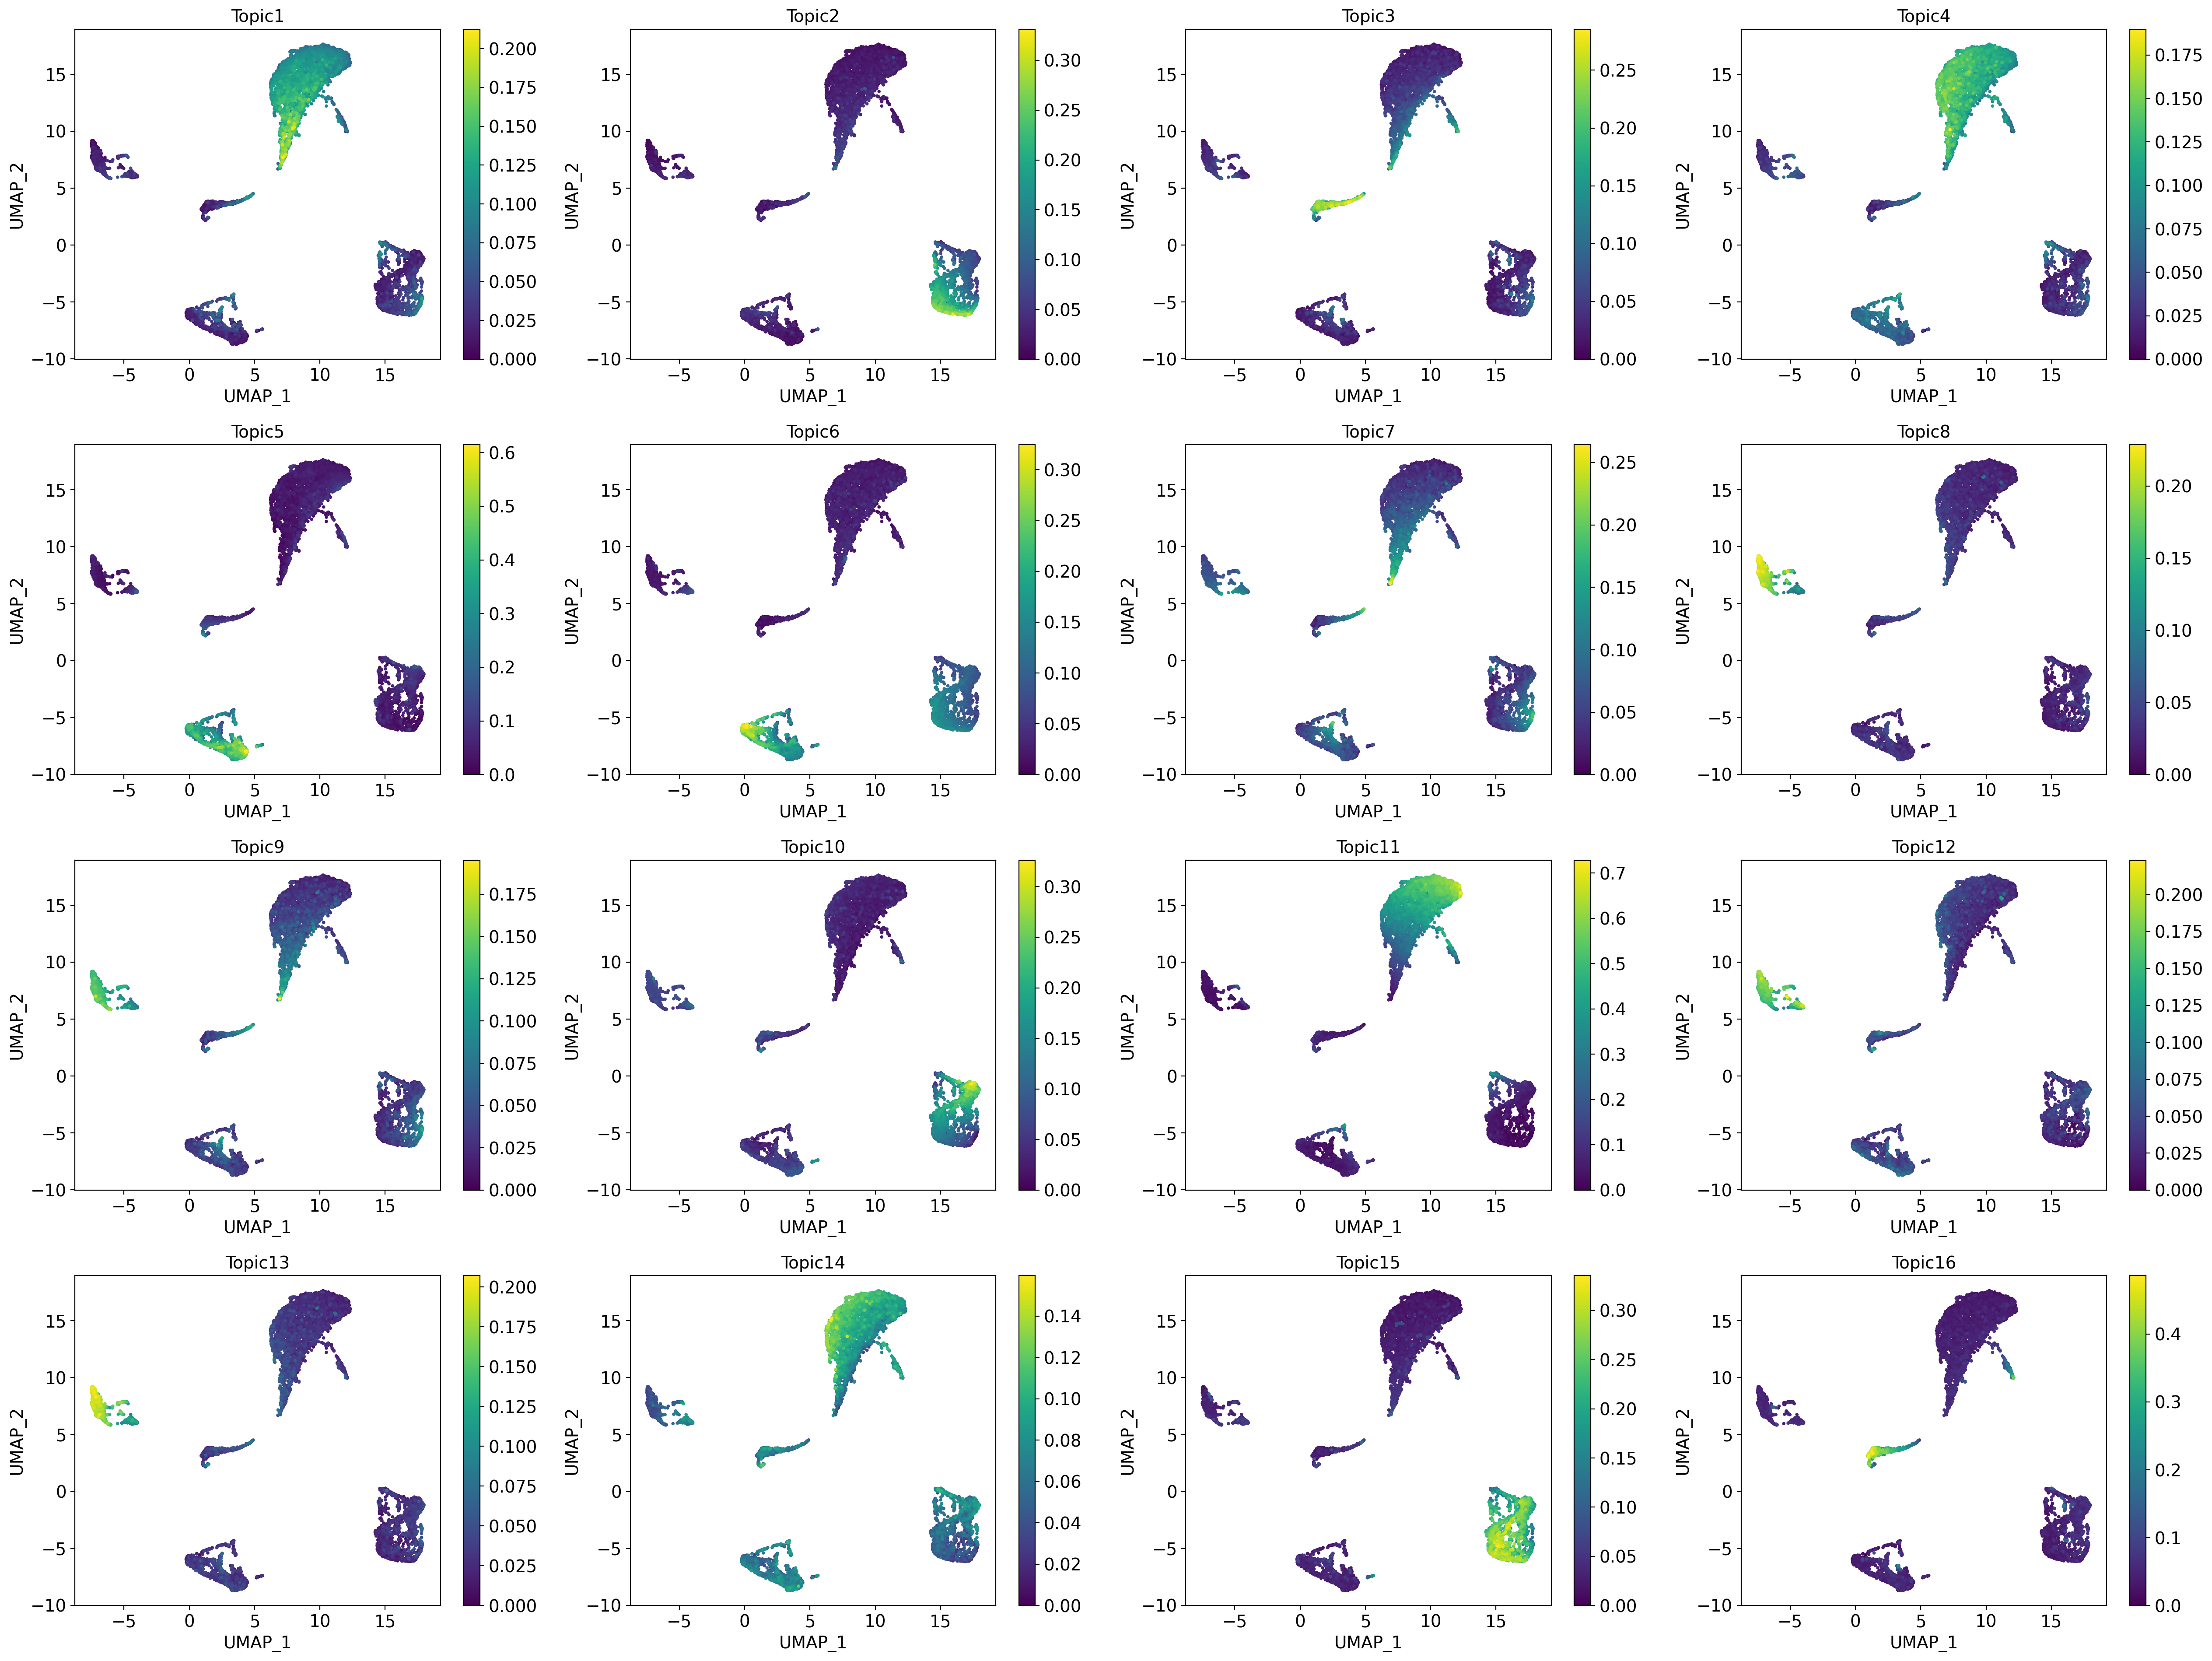

In [6]:
plt.rcParams["axes.grid"] = False
plot_topic(cistopic_obj, reduction_name = 'UMAP', num_columns = 4, dot_size = 3)


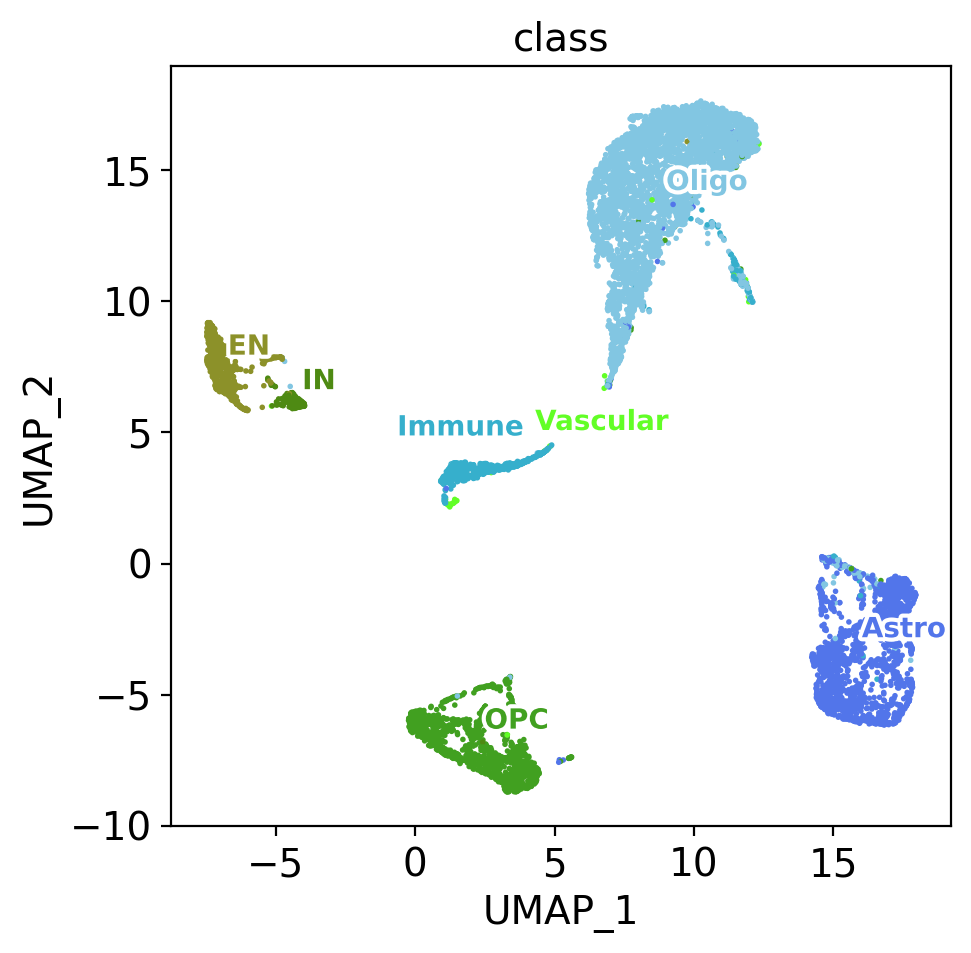

In [7]:
plot_metadata(cistopic_obj, reduction_name = 'UMAP', variables = ['class'],dot_size = 1,figsize = (5,5))

# 7. Topic binarization & QC

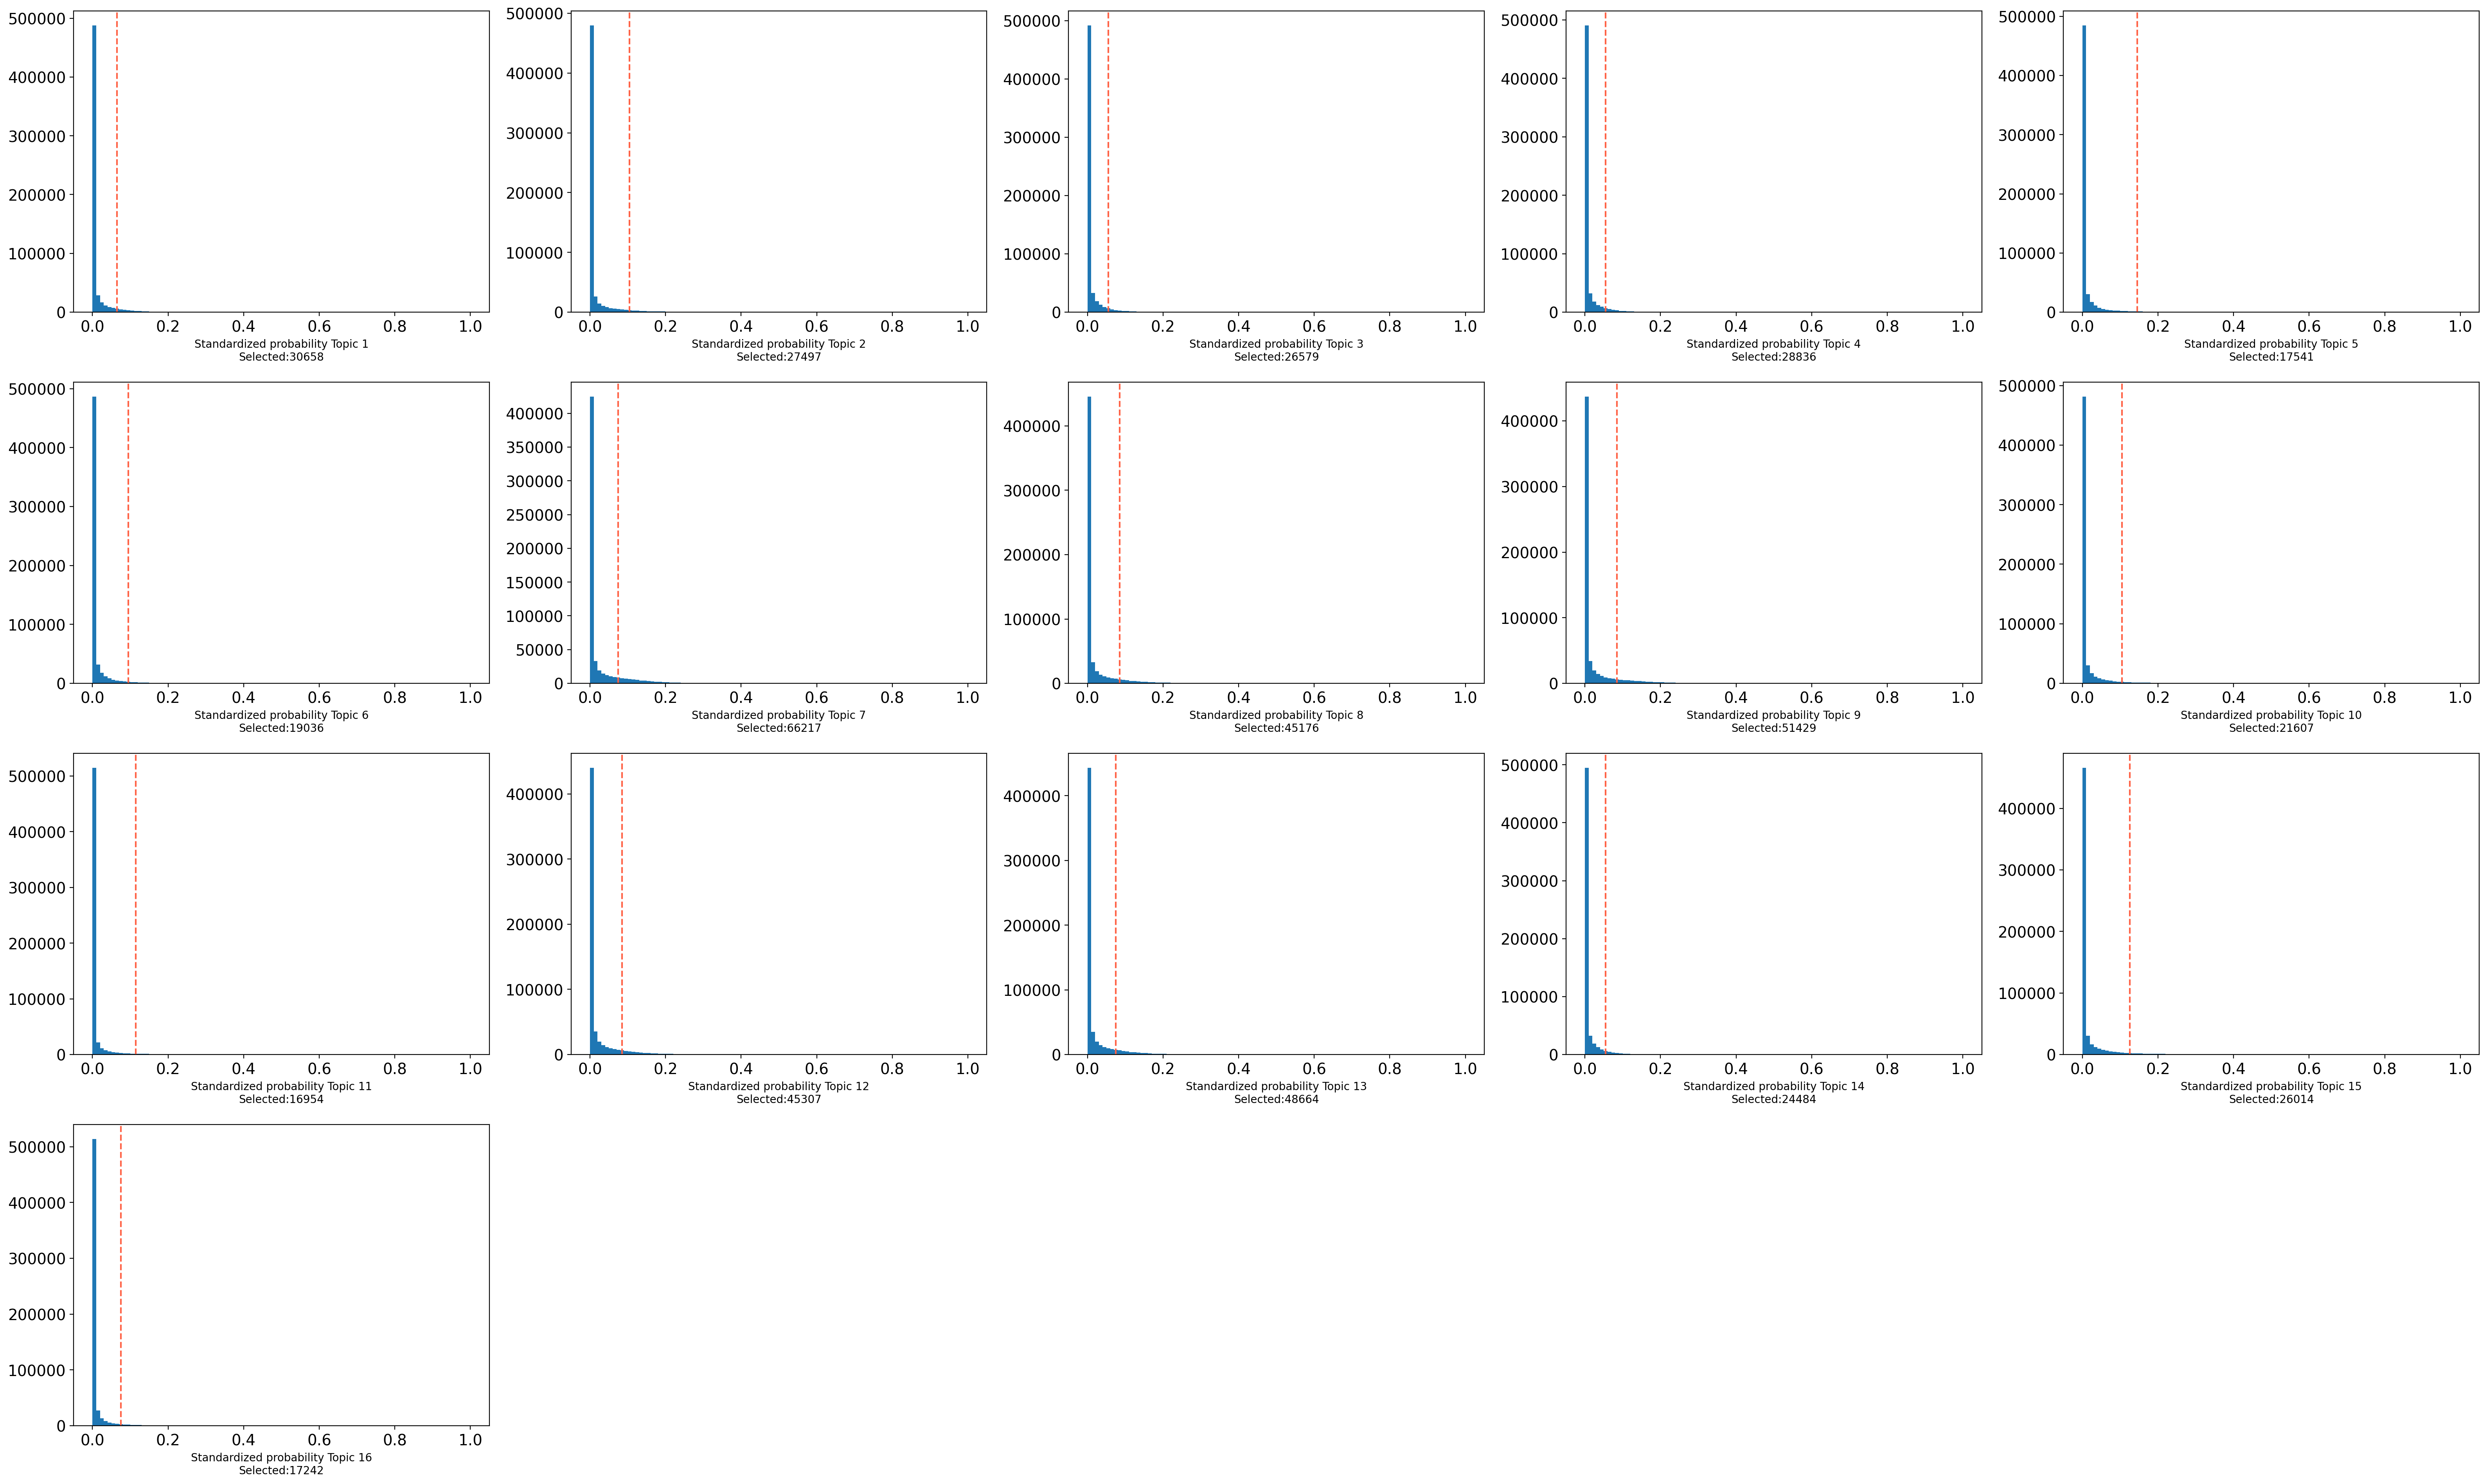

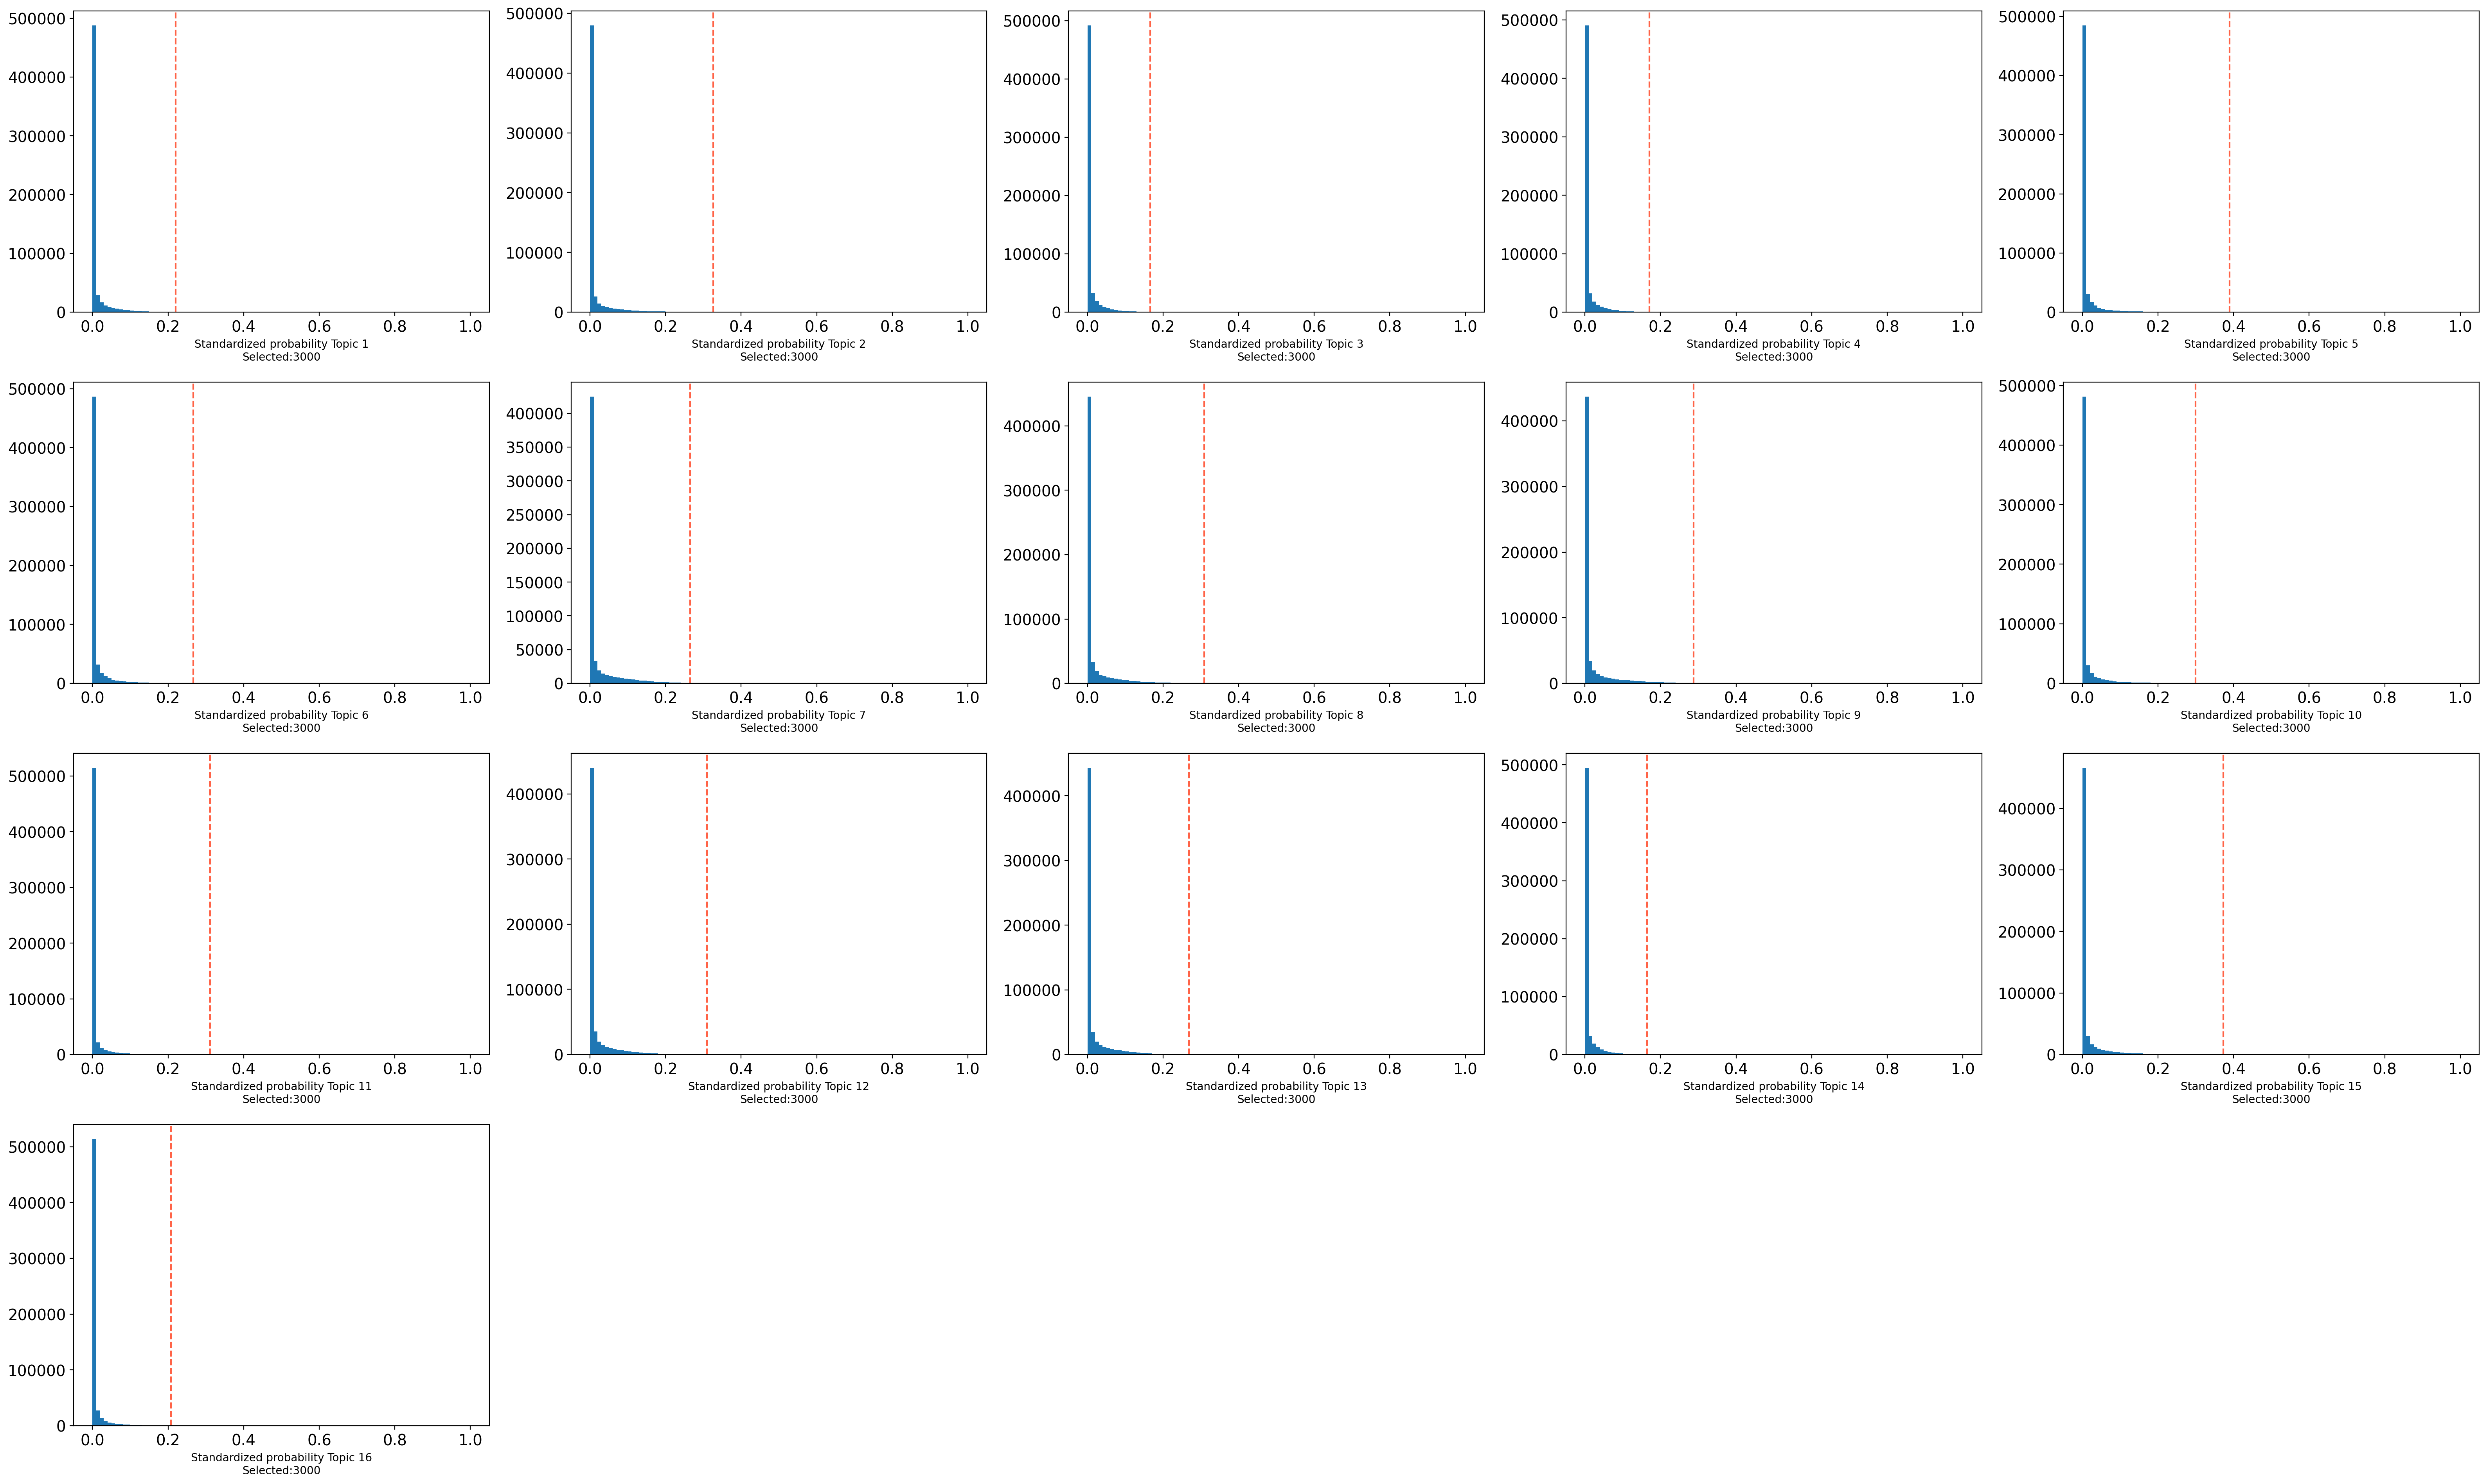

In [8]:
# binarize the topics using the otsu method and by taking the top 3k regions per topic
from pycisTopic.topic_binarization import *
region_bin_topics_otsu = binarize_topics(cistopic_obj, method='otsu',plot=True, num_columns=5)
region_bin_topics_top3k = binarize_topics(cistopic_obj, method='ntop', ntop = 3000,plot=True, num_columns=5)

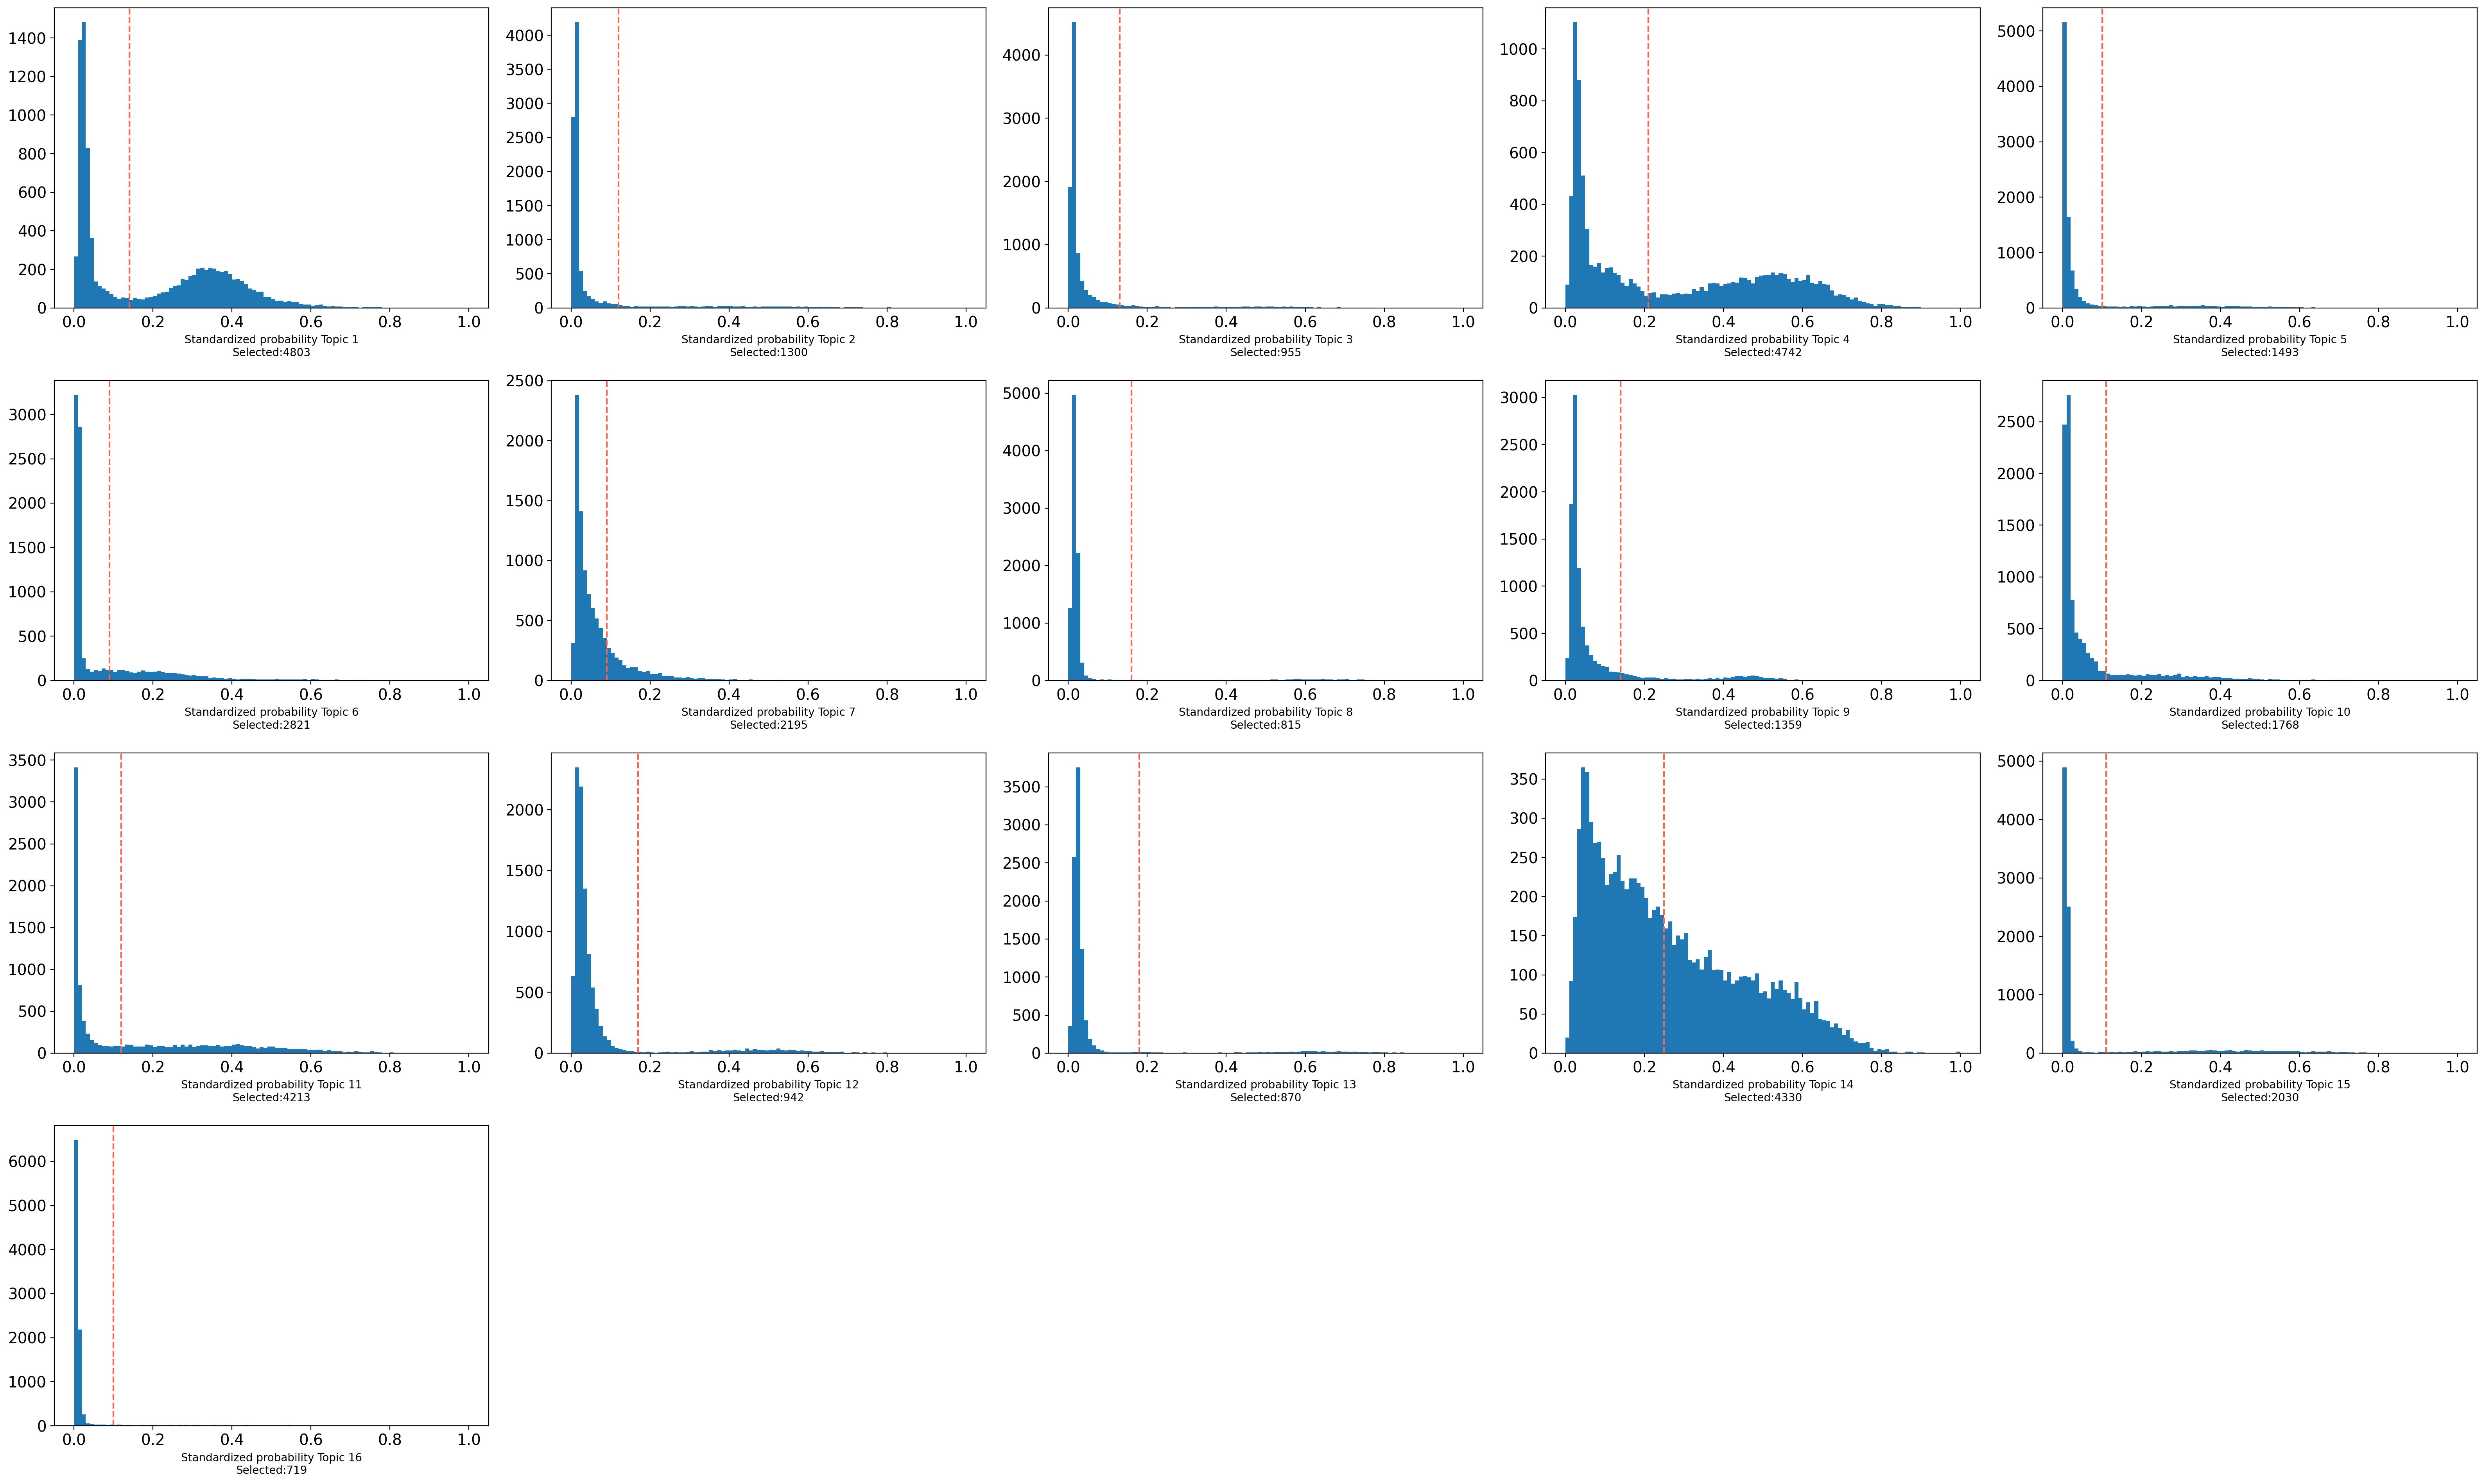

In [9]:
binarized_cell_topic = binarize_topics(
    cistopic_obj,
    target='cell',
    method='li',
    plot=True,
    num_columns=5, nbins=100)

In [10]:
from pycisTopic.topic_qc import compute_topic_metrics, plot_topic_qc, topic_annotation
import matplotlib.pyplot as plt
from pycisTopic.utils import fig2img

In [11]:
topic_qc_metrics = compute_topic_metrics(cistopic_obj)

In [12]:
fig_dict={}
fig_dict['CoherenceVSAssignments']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Log10_Assignments', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['AssignmentsVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Log10_Assignments', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSRegions_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Regions_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSMarginal_dist']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Marginal_topic_dist', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSGini_index']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Gini_index', var_color='Gini_index', plot=False, return_fig=True)

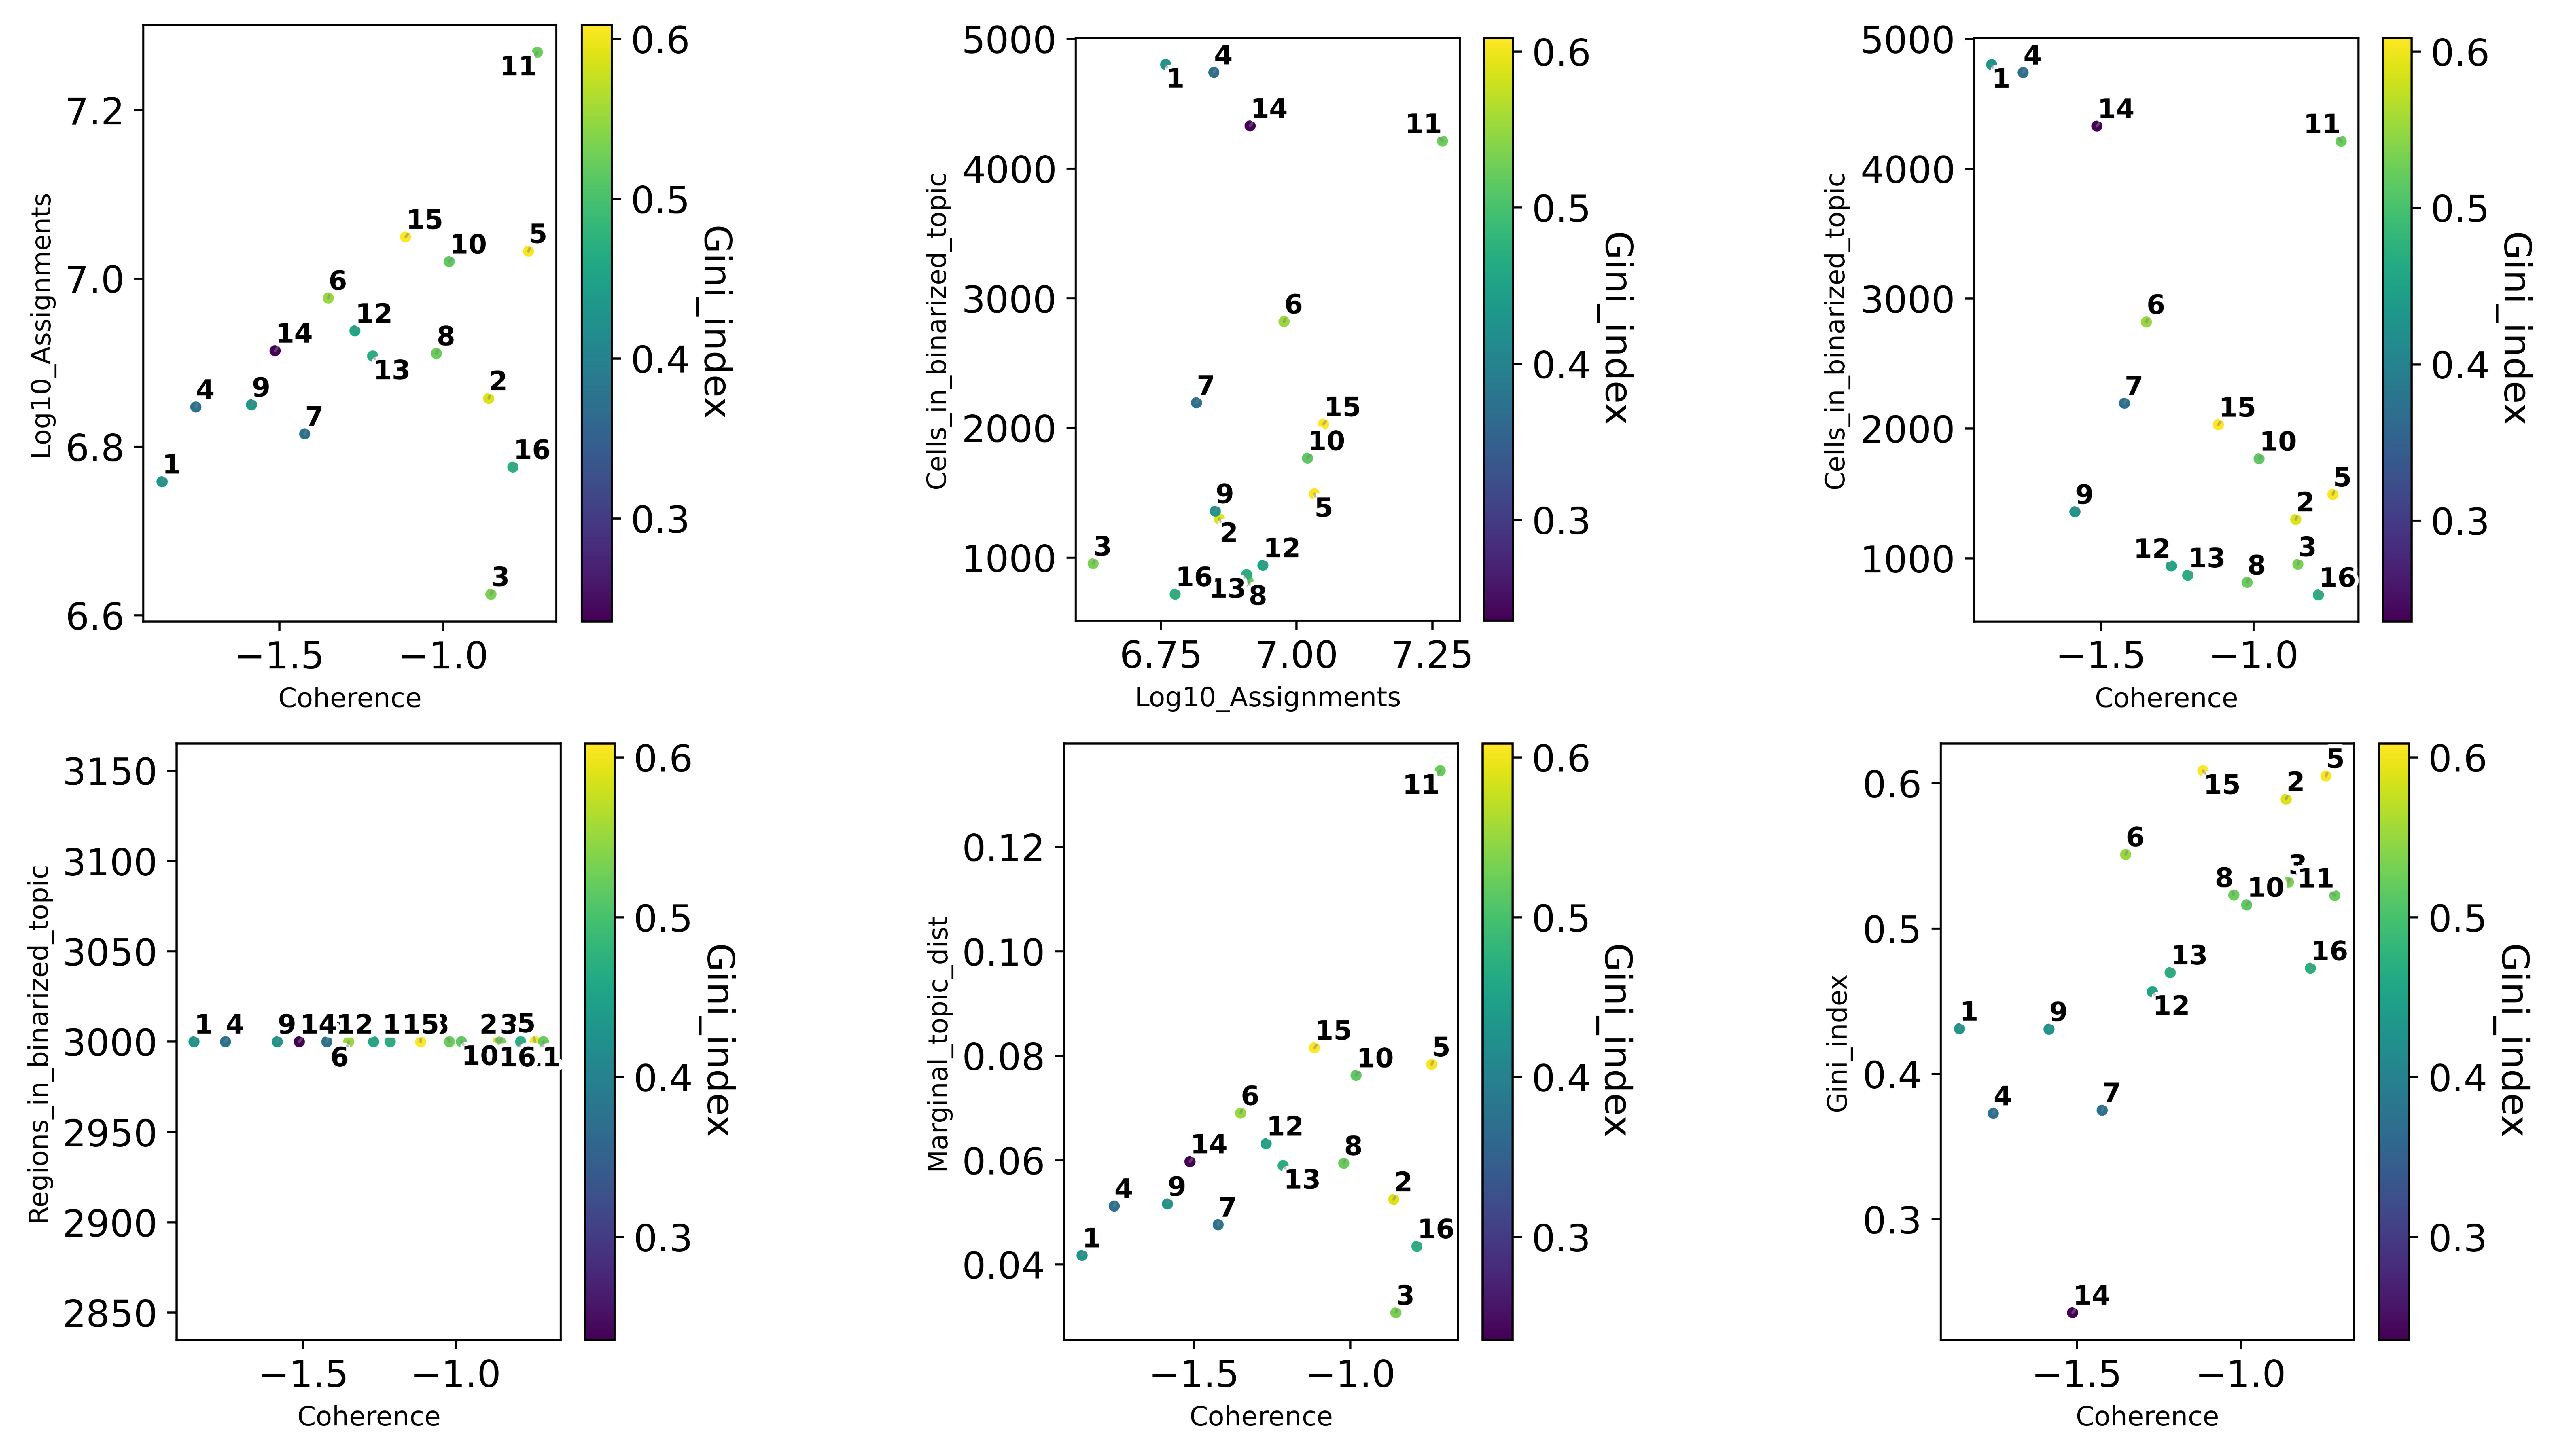

In [13]:
# Plot topic stats in one figure
fig=plt.figure(figsize=(60, 33))
i = 1
for fig_ in fig_dict.keys():
    plt.subplot(2, 3, i)
    img = fig2img(fig_dict[fig_]) #To convert figures to png to plot together, see .utils.py. This converts the figure to png.
    plt.imshow(img)
    plt.axis('off')
    i += 1
plt.subplots_adjust(wspace=0, hspace=-0.01)
plt.show()

In [15]:
topic_annot = topic_annotation(
    cistopic_obj,
    annot_var='class',
    binarized_cell_topic=binarized_cell_topic,
    general_topic_thr = 0.2
)

In [16]:
topic_annot

,class,Ratio_cells_in_topic,Ratio_group_in_population,is_general
Topic1,Oligo,0.487317,0.475852,False
Topic2,Astro,0.131899,0.200893,False
Topic3,Immune,0.096895,0.071226,False
Topic4,Oligo,0.481128,0.475852,False
Topic5,OPC,0.151481,0.153003,False
Topic6,"Astro, OPC",0.286222,0.353896,False
Topic7,"EN, Immune, IN",0.222707,0.165483,False
Topic8,"EN, IN",0.082691,0.094257,False
Topic9,"EN, IN",0.137886,0.094257,False
Topic10,Astro,0.179383,0.200893,False


In [17]:
import pickle
pickle.dump(region_bin_topics_otsu, open(f'{cistopic_dir}/region_bin_topics_otsu.pkl', 'wb'))
pickle.dump(region_bin_topics_top3k, open(f'{cistopic_dir}/region_bin_topics_top3k.pkl', 'wb'))


# 8. Differentially Accessible Regions (DARs)
Together with working with regulatory topics, we can also identify differentially accessible regions (DARs) between cell types. First, we will impute the region accessibility exploting the cell-topic and topic-region probabilities. To shrink very low probability values to 0, we use a scale factor (by default: 10^6).

In [19]:
from pycisTopic.diff_features import (
    impute_accessibility,
    normalize_scores,
    find_highly_variable_features,
    find_diff_features
)

In [20]:
imputed_acc_obj = impute_accessibility(
    cistopic_obj,
    selected_cells=None,
    selected_regions=None,
    scale_factor=10**6
)

2026-06-12 19:27:40,150 cisTopic     INFO     Imputing drop-outs
2026-06-12 19:27:51,959 cisTopic     INFO     Scaling
2026-06-12 19:28:03,494 cisTopic     INFO     Keep non zero rows
2026-06-12 19:28:16,659 cisTopic     INFO     Imputed accessibility sparsity: 0.5326049393648504
2026-06-12 19:28:16,660 cisTopic     INFO     Create CistopicImputedFeatures object
2026-06-12 19:28:16,661 cisTopic     INFO     Done!


In [21]:
normalized_imputed_acc_obj = normalize_scores(imputed_acc_obj, scale_factor=10**4)


2026-06-12 19:28:28,688 cisTopic     INFO     Normalizing imputed data
2026-06-12 19:29:18,741 cisTopic     INFO     Done!


2026-06-12 19:29:18,748 cisTopic     INFO     Calculating mean
2026-06-12 19:29:23,861 cisTopic     INFO     Calculating variance


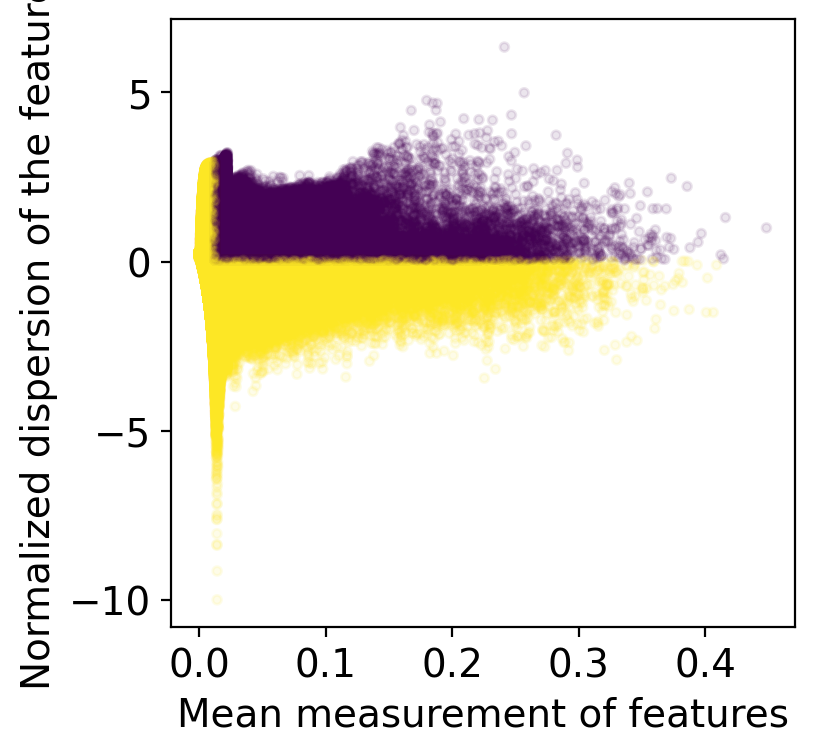

2026-06-12 19:30:07,820 cisTopic     INFO     Done!


In [22]:
variable_regions = find_highly_variable_features(
    normalized_imputed_acc_obj,
    min_disp = 0.05,
    min_mean = 0.0125,
    max_mean = 3,
    max_disp = np.inf,
    n_bins=20,
    n_top_features=None,
    plot=True
)

In [25]:
len(variable_regions)

76856

In [26]:
markers_dict= find_diff_features(
    cistopic_obj,
    imputed_acc_obj,
    variable='class',
    var_features=variable_regions,
    contrasts=None,
    adjpval_thr=0.05,
    log2fc_thr=np.log2(1.5),
    n_cpu=5,
    _temp_dir=tmp_dir,
    split_pattern = '#'
)

2026-06-13 06:48:49,335	INFO worker.py:1743 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


(markers_ray pid=2684570) 2026-06-13 06:49:04,250 cisTopic     INFO     Formatting data for Astro
(markers_ray pid=2684574) 2026-06-13 06:49:04,250 cisTopic     INFO     Formatting data for EN
(markers_ray pid=2684573) 2026-06-13 06:49:04,250 cisTopic     INFO     Formatting data for IN
(markers_ray pid=2684572) 2026-06-13 06:49:04,250 cisTopic     INFO     Formatting data for Immune
(markers_ray pid=2684571) 2026-06-13 06:49:04,250 cisTopic     INFO     Formatting data for OPC
(markers_ray pid=2684574) 2026-06-13 06:49:14,130 cisTopic     INFO     Computing p-value for EN
(markers_ray pid=2684573) 2026-06-13 06:49:14,266 cisTopic     INFO     Computing p-value for IN
(markers_ray pid=2684570) 2026-06-13 06:49:14,415 cisTopic     INFO     Computing p-value for Astro
(markers_ray pid=2684572) 2026-06-13 06:49:14,617 cisTopic     INFO     Computing p-value for Immune
(markers_ray pid=2684571) 2026-06-13 06:49:14,802 cisTopic     INFO     Computing p-value for OPC
(markers_ray pid=2684570

In [27]:
print("Number of DARs found:")
print("---------------------")
for x in markers_dict:
    print(f"  {x}: {len(markers_dict[x])}")

Number of DARs found:
---------------------
  Astro: 32435
  EN: 11923
  IN: 11386
  Immune: 10866
  OPC: 21413
  Oligo: 26507
  Vascular: 7496


In [28]:
pickle.dump(markers_dict, open(f'{cistopic_dir}/DAR_dict.pkl', 'wb'))

# 9. Export cistopic object

In [24]:
cistopic_obj_path = f'{cistopic_dir}/cistopic_obj.pkl'
pickle.dump(cistopic_obj,open(cistopic_obj_path, 'wb'))